# Training

In [11]:
import sys
sys.path.append("..")

import torch
from torch import nn
from torch.utils import data
from tqdm import tqdm
from matplotlib import pyplot as plt

from ai.dataset import ChessDataset, split_by_game
from ai.model import ChessModel

## Hyperparameters

In [2]:
batch_size = 128
learning_rate = 0.001
num_epochs = 5

## Data

In [3]:
dataset = ChessDataset("../data/positions.csv")
train_dataset, val_dataset, test_dataset = split_by_game(dataset)

train_loader = data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print("Train:", len(train_dataset), " val:", len(val_dataset), " test:", len(test_dataset))

Train: 1404996  val: 176674  test: 175981


## Model

In [4]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

model = ChessModel(num_inputs=448, num_hidden=400, num_layers=5, num_outputs=4096)
model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss_fn = nn.CrossEntropyLoss()

print(model)

ChessModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden): ModuleList(
    (0): Linear(in_features=448, out_features=400, bias=True)
    (1-4): 4 x Linear(in_features=400, out_features=400, bias=True)
  )
  (act_fn): ReLU()
  (output): Linear(in_features=400, out_features=4096, bias=True)
)


## Training loop

In [5]:
def train_one_epoch(model, optimizer, train_loader, loss_fn):
    model.train()
    total_loss, num_batches = 0., 0

    for data_inputs, data_labels in tqdm(train_loader):
        data_inputs = data_inputs.to(device)
        data_labels = data_labels.to(device)

        preds = model(data_inputs)
        loss = loss_fn(preds, data_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        num_batches += 1

    return total_loss / num_batches

In [6]:
def eval_model(model, data_loader, loss_fn):
    model.eval()
    total_loss, num_batches = 0., 0
    true_preds, num_preds = 0., 0.

    with torch.no_grad():
        for data_inputs, data_labels in data_loader:
            data_inputs, data_labels = data_inputs.to(device), data_labels.to(device)
            preds = model(data_inputs)

            total_loss += loss_fn(preds, data_labels).item()
            num_batches += 1

            pred_labels = preds.argmax(dim=1)
            true_preds += (pred_labels == data_labels).sum().item()
            num_preds += data_labels.shape[0]

    return total_loss / num_batches, true_preds / num_preds

In [7]:
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, optimizer, train_loader, loss_fn)
    val_loss, val_acc = eval_model(model, val_loader, loss_fn)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1}: train loss {train_loss:.3f}, val loss {val_loss:.3f}, val acc {100.0 * val_acc:4.2f}%")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "../models/best_model.tar")
        print("Checkpoint saved")

100%|██████████| 10977/10977 [19:23<00:00,  9.44it/s]


Epoch 1: train loss 5.498, val loss 5.045, val acc 11.38%
Checkpoint saved


  5%|▍         | 528/10977 [00:58<19:22,  8.99it/s]


KeyboardInterrupt: 

## Results

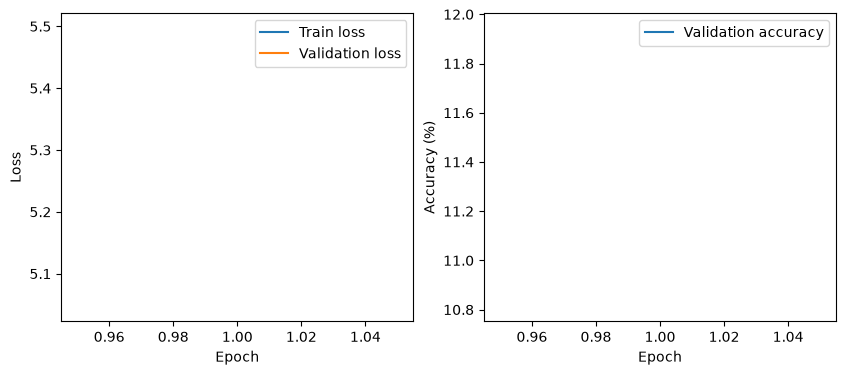

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, [100.0 * acc for acc in history["val_acc"]], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.show()